# Risoluzione di equazioni non lineari

L'obiettivo è risolvere l'equazione:

$$f(x)=0$$

dove $f:[a,b] \rightarrow  R$ è una funzione continua.
Questa equazione in generale non è risolubile con tecnoche analitiche, a meno di casi particolari di funzioni $f(x)$.

*Condizioni di esistenza e unicità della soluzione nel continuo*

Se $f$ è una funzione continua in [a,b] e tale che $f(a)f(b)<0$,
allora esiste almeno uno zero di $f$ in $(a,b)$.



 

Il problema è determinare le radici di un'equazione non lineare

$$
f(x)=0,
$$

dove $f$ è una funzione reale di variabile reale.

Una radice, o zero, è un valore $x^{*}$ tale che

$$
f(x^{*})=0.
$$

Nelle applicazioni, raramente esiste una formula esplicita per calcolare $x^{*}$.  
Per questo motivo si usano **metodi numerici iterativi**.

Un metodo iterativo costruisce una successione

$$
x_0, x_1, x_2, \ldots
$$

che, sotto opportune ipotesi, converge alla radice desiderata:

$$
\lim_{k\to\infty}x_k=x^{*}.
$$

### Esempio introduttivo

Consideriamo

$$
f(x)=x^2-2.
$$

Le radici sono

$$
x=\pm\sqrt{2}.
$$

Se vogliamo approssimare la radice positiva, possiamo cercarla numericamente nell'intervallo $[1,2]$, perché

$$
f(1)=-1<0,
$$

mentre

$$
f(2)=2>0.
$$

Il cambio di segno suggerisce, per continuità, che esiste almeno uno zero fra 1 e 2.

In [46]:
import math
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=12, suppress=True)

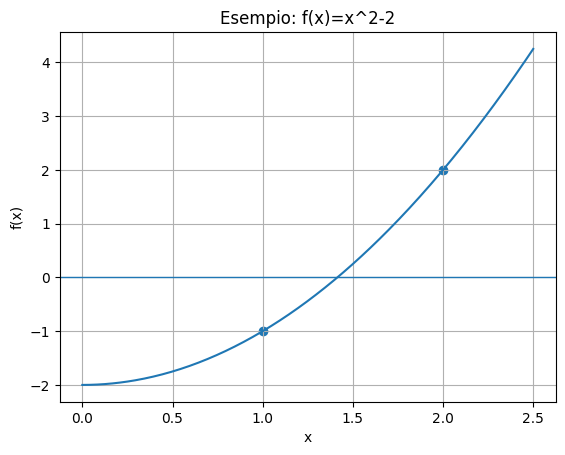

In [47]:


def f_intro(x):
    return x**2 - 2

xs = np.linspace(0, 2.5, 300)
ys = f_intro(xs)

plt.figure()
plt.axhline(0, linewidth=1)
plt.plot(xs, ys)
plt.scatter([1, 2], [f_intro(1), f_intro(2)])
plt.title("Esempio: f(x)=x^2-2")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True)
plt.show()

### Numero di soluzioni di un'equazione non lineare

Un'equazione non lineare può avere comportamenti molto diversi rispetto al numero di soluzioni.

Una equazione del tipo

$$
f(x)=0
$$

può avere:

- nessuna soluzione reale;
- una sola soluzione reale;
- due o più soluzioni reali;
- un numero arbitrariamente grande di soluzioni;
- infinite soluzioni.

Questo è uno dei motivi per cui non esiste un unico metodo universale che risolva automaticamente tutte le equazioni non lineari.  
Prima di applicare un metodo numerico è spesso utile osservare il grafico della funzione o studiarne alcune proprietà qualitative.

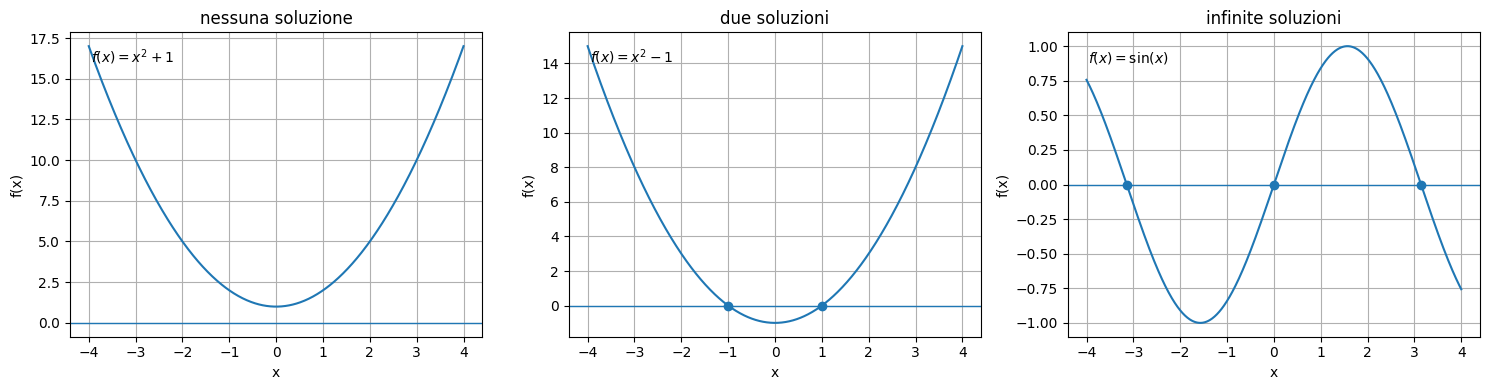

In [48]:
# Esempi di equazioni non lineari con diverso numero di soluzioni reali.

x = np.linspace(-4, 4, 800)

funzioni = [
    (lambda x: x**2 + 1, "nessuna soluzione", r"$f(x)=x^2+1$"),
    (lambda x: x**2 - 1, "due soluzioni", r"$f(x)=x^2-1$"),
    (lambda x: np.sin(x), "infinite soluzioni", r"$f(x)=\sin(x)$"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (f, titolo, formula) in zip(axes, funzioni):
    y = f(x)
    ax.plot(x, y)
    ax.axhline(0, linewidth=1)
    ax.set_title(titolo)
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.grid(True)
    ax.text(0.05, 0.9, formula, transform=ax.transAxes)

    # Evidenziamo gli zeri visibili nei casi in cui sono noti.
    if titolo == "due soluzioni":
        ax.scatter([-1, 1], [0, 0], zorder=3)
    if titolo == "infinite soluzioni":
        zeri = np.arange(-3, 4) * np.pi
        zeri = zeri[(zeri >= x.min()) & (zeri <= x.max())]
        ax.scatter(zeri, np.zeros_like(zeri), zorder=3)

plt.tight_layout()
plt.show()



Una equazione come

$$
x^2-2=0
$$

ha una soluzione nota in forma chiusa.

Ma equazioni come

$$
\cos(x)-x=0,
$$

oppure

$$
e^{-x}-x=0,
$$

non hanno, in generale, una soluzione esprimibile con funzioni elementari.

In questi casi vogliamo calcolare una approssimazione $\tilde{x}$ tale che:

- $\tilde{x}$ sia vicina alla radice vera $x^{*}$;
- il _residuo_ $|f(\tilde{x})|$ sia piccolo;
- il calcolo sia stabile e non troppo costoso.

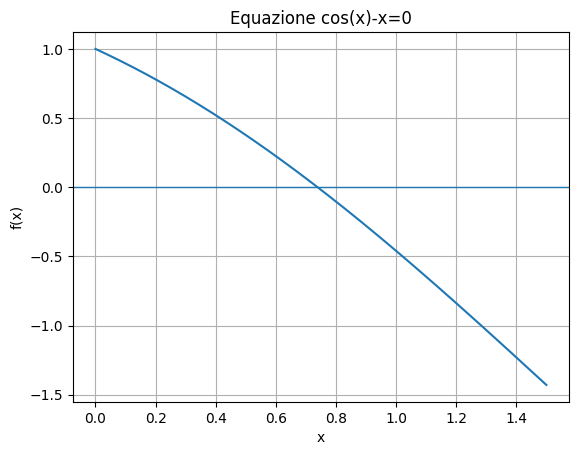

In [49]:
def f_cos(x):
    return np.cos(x) - x

xs = np.linspace(0, 1.5, 400)
ys = f_cos(xs)

plt.figure()
plt.axhline(0, linewidth=1)
plt.plot(xs, ys)
plt.title("Equazione cos(x)-x=0")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True)
plt.show()

 **Molteplicità di una radice**

Una radice $\alpha$ di una funzione $f$ è detta **radice di molteplicità** $m$ se si può scrivere

$$
f(x)=(x-\alpha)^m q(x),
$$

dove $q$ è una funzione continua e

$$
q(\alpha)\neq 0.
$$

In particolare:

- se $m=1$, la radice è **semplice**;
- se $m>1$, la radice è **multipla**.

Per i polinomi, questa definizione coincide con il numero di volte in cui il fattore $(x-\alpha)$ compare nella fattorizzazione.

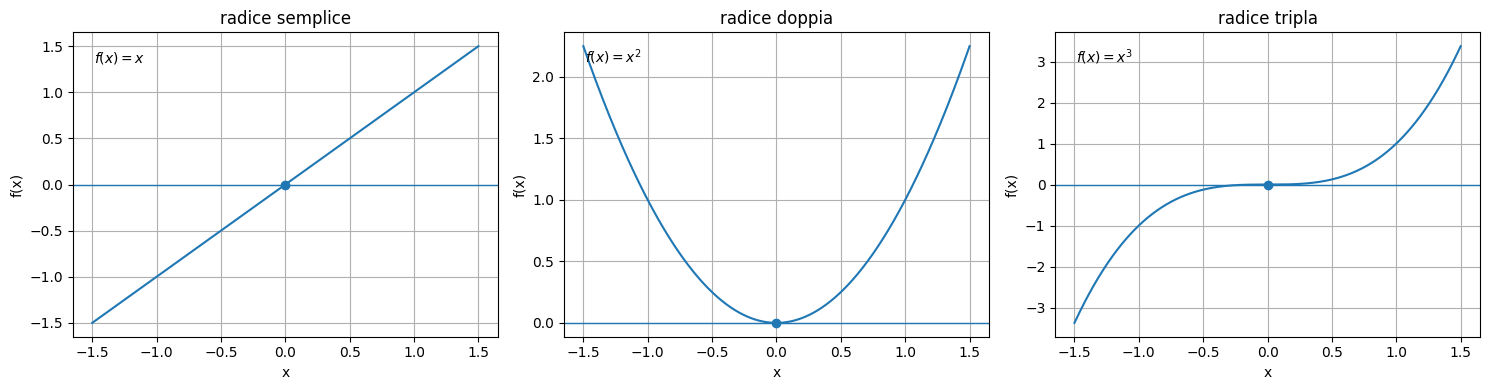

In [50]:
# Radici semplici, doppie e triple a confronto.

x = np.linspace(-1.5, 1.5, 600)
alpha = 0.0

f_simple = x
f_double = x**2
f_triple = x**3

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(x, f_simple)
axes[0].axhline(0, linewidth=1)
axes[0].scatter([alpha], [0], zorder=3)
axes[0].set_title("radice semplice")
axes[0].text(0.05, 0.9, r"$f(x)=x$", transform=axes[0].transAxes)

axes[1].plot(x, f_double)
axes[1].axhline(0, linewidth=1)
axes[1].scatter([alpha], [0], zorder=3)
axes[1].set_title("radice doppia")
axes[1].text(0.05, 0.9, r"$f(x)=x^2$", transform=axes[1].transAxes)

axes[2].plot(x, f_triple)
axes[2].axhline(0, linewidth=1)
axes[2].scatter([alpha], [0], zorder=3)
axes[2].set_title("radice tripla")
axes[2].text(0.05, 0.9, r"$f(x)=x^3$", transform=axes[2].transAxes)

for ax in axes:
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.grid(True)

plt.tight_layout()
plt.show()

### Osservazione geometrica

Se la molteplicità è pari, la funzione spesso tocca l'asse $x$ senza attraversarlo.  
Questo significa che metodi basati sul cambio di segno, come la bisezione, possono non individuare direttamente la radice.

Se la molteplicità è dispari, la funzione attraversa l'asse $x$, ma può farlo in modo molto piatto.  
Anche in questo caso il problema può essere più difficile numericamente.

*Algoritmi per calcolare la soluzione: metodi iterativi*

- Non è possibile in
generale costruire metodi numerici che calcolino le radici di
un'equazione non lineare in un numero finito di passi.
-  I metodi per questo tipo di problema sono **metodi iterativi.**

-  A partire da uno o pi\ug dati iniziali, calcolano dei valori
$x_k$ attraverso un procedimento che si ripete (itera) sempre uguale
ad ogni passo k: 

$$x_k=G(x_{k-1})$$

-  Si crea quindi una successione che deve avere la proprieta di essere convergente e di convergere alla soluzione esatta, cioè sotto opportune
condizioni gli iterati $x_k$ convergono alla soluzione $x^*$ (tale
che $f(x^*)=0$) per $k \rightarrow \infty$.
 Schema algoritmo iterativo:

1. Dati: $x_0$
 
2.k=1 
 
3. Ripeti finchè convergenza

     3.1 $x_k=G(x_{k-1})$

     3.2  $k=k+1$ 

end

Sono da specificare nel singolo metodo le condizioni di convergenza
che  regolano l'arresto del ciclo "ripeti".

**Ordine di convergenza dei metodi iterativi**

Si dice che la successione ${x_k}$ generata da un metodo iterativo
converge ad $x^*$ con ordine $p\geq 1$ se:
$$ \frac{|x_{k+1}-x^*a|}{|x_k-x^*|^p}= C, \forall
k\geq k_0$$dove $k_0$ \eg un intero opportuno e $C \in R$ tale che:

$$
\bigg \{
\begin{array}{rrl}
0<C\leq 1 & se & p=1 \\
C>0 & se &p>1 \\
\end{array}
$$

 In tal caso si dice che **il metodo è di ordine$p$**.

*Osservazione*. nel caso $p=1$ per avere convergenza deve
essere $C<1$. In questo caso $C$ prende il nome di *fattore di
convergenza.*


In [51]:
# Simulazione di convergenza lineare e quadratica

errors_linear = [1e-1]
errors_quad = [1e-1]

for k in range(8):
    errors_linear.append(0.5 * errors_linear[-1])
    errors_quad.append(2.0 * errors_quad[-1]**2)

print("k   lineare        quadratica")
for k, (el, eq) in enumerate(zip(errors_linear, errors_quad)):
    print(f"{k:1d}   {el:.3e}      {eq:.3e}")

k   lineare        quadratica
0   1.000e-01      1.000e-01
1   5.000e-02      2.000e-02
2   2.500e-02      8.000e-04
3   1.250e-02      1.280e-06
4   6.250e-03      3.277e-12
5   3.125e-03      2.147e-23
6   1.563e-03      9.223e-46
7   7.813e-04      1.701e-90
8   3.906e-04      5.790e-180


In generale la convergenza di un
metodo iterativo per la risoluzione di un'equazione non lineare
dipende dalla scelta del valore iniziale $x_0$.

Esisteranno quindi risultati di **convergenza globale** quando
il metodo converge per **ogni**
scelta di $x_0$ e teoremi di **convergenza locale** quando il
metodo converge solo se $x_0$ è scelto in un
opportuno intorno della radice
esatta.


**Algoritmi per il calcolo di uno zero della funzione $f$*

- Metodo di bisezione
- Metodo del punto fisso
- Metodo di Newton



### Metodo di bisezione

Si costruisce una successione di
intervalli ($f(a_1)<0,f(b_1)>0$):
$$I_1=[a_1,b_1],I_2=[a_2,b_2], \ldots ,I_k=[a_k,b_k]$$
tali che:$$I_k\subset I_{k-1} \subset \ldots \subset I_1$$ con
$f(a_k)f(b_k)<0, k=1,2 \ldots$. ($a_1=a,b_1=b$). Al passo $k$ si
calcola $$c_k=\frac{a_k+b_k}{2}, \quad k=1,2 \ldots $$e il valore
$f(c_k)$. Se $f(c_k)=0,c_k=x^*$, altrimenti:
$$[a_{k+1},b_{k+1}]=\left\{
                      \begin{array}{ll}
                        [a_k,c_k], & \hbox{se $f(c_k)>0$}\\
                        1 [c_k,b_k], & \hbox{se $f(c_k)<0$.}
                      \end{array}
                    \right.
$$


*Osservazioni sulla implementazione dell'algoritmo con i numeri finiti*


- $c=a+\frac{b-a}{2}$ altrimenti $c_{k+1}$ pu\og cadere esterno
all'intervallo $[a_k,b_k]$.

esempio: $a=0.983,b=0.986$,$\mathbb{F}(10,3,-5,5)$.

-  $f(a)f(b)$ pu\og non essere rappresentabile sulla macchina.
per verificare il segno conviene quindi usare la funzione $sign(f)$

- L'algoritmo in aritmetica
finita pu\og non avere fine.

esempio: $a_k=98.5$, $b_k=98.6$, $\epsilon=0.004$ in
$\mathbb{F}(10,3,-5,5)$. Infatti $c_k=98.55$, ma $fl(c_k)=0.985\cdot
10^{2}$, quindi si genera una successione di iterati costanti.

Test modificato: $$|b_k-a_k|<\epsilon +eps\cdot max(|b|,|a|) \quad
\& \quad iter<itmax$$ dove $eps$ è la precisione di
macchina.


**Convergenza del metodo di bisezione**

Al passo $k$,
$$b_{k+1}-a_{k+1}=\frac{1}{2}(b_k-a_k)=\frac{1}{2^2}(b_{k-1}-a_{k-1})=
\ldots =\frac{1}{2^k}(b_1-a_1)$$ quindi
$x^*=c_{k+1}\pm\epsilon_{k+1}$, dove

$$\epsilon_{k+1}\leq
\frac{1}{2^{k+1}}(b-a).$$ 

Viceversa, fissato $\epsilon$ tale che
$\epsilon=\frac{1}{2^{k+1}}(b-a)$, il numero $c_{k+1}$ \eg una
approssimazione di $x^*$ entro una tolleranza $\epsilon$.

Quindi per
$k\rightarrow \infty$, $\{c_k\} \rightarrow x^*$ con velocità di
convergenza pari a quella della successione $\{\frac{1}{2^k}\}$.

Il metodo fornisce inoltre una maggiorazione dell'errore, cioè
fissata una tolleranza $\delta$ è possibile determinare il numero
minimo di iterazioni $k$ per ottenere un errore minore di $\delta$.
Infatti $k$ è tale che:
$$\frac{1}{2^k}(b-a)<\delta \Rightarrow 2^k\geq
\frac{b-a}{\delta}\Rightarrow$$
$$k\geq log_2\frac{b-a}{\delta}$$
**Complessità computazionale del metodo**: ad ogni iterazione
occorrono 2 valutazioni di funzione.

In [52]:
def bisection(f, a, b, tol=1e-12, max_iter=100, return_history=True):
    fa = f(a)
    fb = f(b)

    if fa == 0:
        return (a, 0, []) if return_history else (a, 0)
    if fb == 0:
        return (b, 0, []) if return_history else (b, 0)

    if fa * fb > 0:
        raise ValueError("La funzione deve cambiare segno in [a,b].")

    history = []

    for k in range(1, max_iter + 1):
        m = 0.5 * (a + b)
        fm = f(m)

        history.append((k, a, b, m, fm, b - a))

        if abs(b - a) <= tol or fm == 0:
            return (m, k, history) if return_history else (m, k)

        if fa * fm < 0:
            b = m
            fb = fm
        else:
            a = m
            fa = fm

    return (0.5 * (a + b), max_iter, history) if return_history else (0.5 * (a + b), max_iter)

In [53]:
root, niter, hist = bisection(lambda x: x**2 - 2, 1, 2, tol=1e-12, return_history=True)

print("Radice approssimata:", root)
print("Iterazioni:", niter)
print("Errore rispetto a sqrt(2):", abs(root - math.sqrt(2)))

Radice approssimata: 1.414213562372879
Iterazioni: 41
Errore rispetto a sqrt(2): 2.1604940059205546e-13




La tabella seguente mostra come si restringe l'intervallo.

In [54]:
for row in hist[:10]:
    k, a, b, m, fm, width = row
    print(f"k={k:2d}, a={a:.12f}, b={b:.12f}, m={m:.12f}, f(m)={fm:.3e}, ampiezza={width:.3e}")

k= 1, a=1.000000000000, b=2.000000000000, m=1.500000000000, f(m)=2.500e-01, ampiezza=1.000e+00
k= 2, a=1.000000000000, b=1.500000000000, m=1.250000000000, f(m)=-4.375e-01, ampiezza=5.000e-01
k= 3, a=1.250000000000, b=1.500000000000, m=1.375000000000, f(m)=-1.094e-01, ampiezza=2.500e-01
k= 4, a=1.375000000000, b=1.500000000000, m=1.437500000000, f(m)=6.641e-02, ampiezza=1.250e-01
k= 5, a=1.375000000000, b=1.437500000000, m=1.406250000000, f(m)=-2.246e-02, ampiezza=6.250e-02
k= 6, a=1.406250000000, b=1.437500000000, m=1.421875000000, f(m)=2.173e-02, ampiezza=3.125e-02
k= 7, a=1.406250000000, b=1.421875000000, m=1.414062500000, f(m)=-4.272e-04, ampiezza=1.562e-02
k= 8, a=1.414062500000, b=1.421875000000, m=1.417968750000, f(m)=1.064e-02, ampiezza=7.812e-03
k= 9, a=1.414062500000, b=1.417968750000, m=1.416015625000, f(m)=5.100e-03, ampiezza=3.906e-03
k=10, a=1.414062500000, b=1.416015625000, m=1.415039062500, f(m)=2.336e-03, ampiezza=1.953e-03


*Numero di iterazioni richieste*

Se vogliamo un errore finale di al più $\mathrm{tol}$, dobbiamo avere

$$
\frac{b_0-a_0}{2^{k+1}}\le \mathrm{tol}.
$$

Da cui

$$
k\ge \log_2\left(\frac{b_0-a_0}{2 \mathrm{tol}}\right).
$$

Quindi il numero di iterazioni cresce solo logaritmicamente rispetto alla tolleranza, ma il metodo rimane relativamente lento perché a ogni passo guadagna circa una cifra binaria.

In [55]:
def bisection_iterations_needed(a, b, tol):
    return math.ceil(math.log2((b - a) / tol))

for tol in [1e-3, 1e-6, 1e-9, 1e-12]:
    print(f"tol={tol:.0e}, iterazioni richieste circa:", bisection_iterations_needed(1, 2, tol))

tol=1e-03, iterazioni richieste circa: 10
tol=1e-06, iterazioni richieste circa: 20
tol=1e-09, iterazioni richieste circa: 30
tol=1e-12, iterazioni richieste circa: 40


**Limiti del metodo di bisezione**

Vantaggi:

- è semplice;
- è robusto;
- converge sempre se $f$ è continua e cambia segno;
- non richiede di valutare la funzione, ma solo il suo segno;
- non richiede derivate.

Svantaggi:

- converge lentamente;
- usa solo il segno di $f$, non la sua forma. Di conseguenza può richiedere infinite iterazioni per calcolare lo zero di una retta $f(x)=ax+b$;
- se in un intervallo ci sono più radici, ne approssima una sola;
- non funziona direttamente per radici di molteplicità pari se non c'è cambio di segno.

### Metodo del punto fisso

Il problema
di cercare una radice di $$f(x)=0$$ viene spostato nel problema di
cercare una soluzione dell'equazione $$x=g(x)$$ cioè un punto
fisso della funzione $g(x)$ dove 

$$g(x)=x-f(x)\Phi(x).$$

**Perchè calcolare $f(x)=0$ è equivalente a calcolare $x=g(x)$ (per una opportuna funzione $g$)?**


Se $f(x)$ si
annulla in $[a,b]$ e $\Phi(x)$ è una funzione tale
che:

$$
0<|\Phi(x)|<\infty, \ \ x \in [a,b]
$$ 

allora :

1) se $f(x)=0$ allora $g(x)=x-0*f(x)=x$

2) se $g(x)=x$ allora, poichè $\Phi(x)$ non si annulla, necessariamente  è $f(x)=0$.

Geometricamente è l'intersezione delle due curve:
$$y=x \ \ \ y=g(x)$$



In [56]:
def fixed_point(g, x0, tol=1e-12, max_iter=100, return_history=False):
    x = float(x0)
    history = [x]

    for k in range(1, max_iter + 1):
        x_new = g(x)
        history.append(x_new)

        if abs(x_new - x) <= tol:
            return (x_new, k, history) if return_history else (x_new, k)

        x = x_new

    return (x, max_iter, history) if return_history else (x, max_iter)

Per potere applicare il metodo numerico, o l'algoritmo, nel caso discreto devono essercinin generale delle condizioni da verificare nel caso continuo. Se non si verificano queste condizioni e quindi non è possibile calcolare la soluzione nel caso continuo, allora non ha senso applicare l'algortimo anche nel caso discreto.

Questo teorema è un esempio di tali condizioni. 

**Teorema di esistenza e unicità del punto fisso nel modello continuo**

Sia $g(x)$ continua in $[a,b]$ e tale che $g(x) \in [a,b]$. Sia $L$
una costante  $0\leq L<1$ tale che, per ogni $x, y \in [a,b]$ si ha:
$$|g(x)-g(y)|\leq L|x-y|$$
ossia $g$ è una contrazione in $[a,b]$. Allora esiste un unico
punto fisso $x^*$ di $g(x)$ in $[a,b]$. 

Come tutti i teoremi ha una dimostrazione che non tratteremo in questo corso (così come in geerale le dimostrazioni dei teoremi) poichè non è la parte teorica il focus del corso e visto il tempo ridotto a disposizione. Per chi ha interesse a vederla potete consultare il testo....


Esempio

L'equazione

$$
\cos(x)-x=0
$$

può essere scritta come

$$
x=\cos(x).
$$

Quindi usiamo

$$
g(x)=\cos(x).
$$

**Algoritmo del punto fisso**

Data una approssimazione iniziale $x_0$ di $x^*$, punto fisso di $g(x)$ in
$[a,b]$, si genera una successione di iterati mediante il metodo delle
approssimazioni successive o del punto fisso o iterazione
funzionale:

$$x_{k+1}=g(x_k)$$

**N.B. in un metodo iterativo, dopo avere espresso la regola per costruire la successione $x_0,x_1, \ldots x_k \ldots$ si devono dare le condizioni per cui questa successione è effettiamnte convergente alla soluzione cercata. Altrimenti non è utilizzabile.**

In [57]:
root, it, hist = fixed_point(np.cos, x0=1.0, tol=1e-12, return_history=True)

print("Punto fisso:", root)
print("Iterazioni:", it)
print("Residuo cos(x)-x:", math.cos(root) - root)

for k, xk in enumerate(hist[:10]):
    print(f"k={k:2d}, x_k={xk:.12f}")

Punto fisso: 0.7390851332147725
Iterazioni: 69
Residuo cos(x)-x: 6.495914917081791e-13
k= 0, x_k=1.000000000000
k= 1, x_k=0.540302305868
k= 2, x_k=0.857553215846
k= 3, x_k=0.654289790498
k= 4, x_k=0.793480358743
k= 5, x_k=0.701368773623
k= 6, x_k=0.763959682901
k= 7, x_k=0.722102425027
k= 8, x_k=0.750417761764
k= 9, x_k=0.731404042423


*Osservazione*

 Se $g(x)$ è derivabile in $[a,b]$ con
$|g'(x)|\leq L<1$ per $x \in [a,b]$, allora $g(x)$ è una
contrazione. Il viceversa non è vero perchè $g(x)$ può non
essere derivabile.



In questo caso ci sono due teoremi che assicurano la convergenza: il primo pone le condizioni affibchè la successione creata sia una successione che converge a un certo punto $x^*$, il secondo teorema assicura che il punto $x^*$ è esattamente il punto voluto, cioè uno zero della funzione $f(x)$.

*Teorema 1 (la successione converge a un punto).*

Se $g(x)$ è continua e la successione $\{x_k\}$ converge per $k
\rightarrow \infty$ a un punto $x^*$, allora $x^*$ è punto fisso
di $g(x)$. Infatti:

$$x^*=\lim_{k \rightarrow \infty} x_{k+1}=\lim_{k \rightarrow \infty}g(
x_{k})=g(\lim_{k \rightarrow \infty} x_{k})=g(x^*)$$

Geometricamente, il metodo dell'iterazione funzionale equivale alla
costruzione di una poligonale orientata con lati orizzontali e
verticali nel piano $xy$.


<p align="center">
  <img src="immagini_sorgente\fig100.png"  width="800">
</p>

<p align="center">
  <img src="immagini_sorgente\fig101.png"  width="600">
</p>

*Teorema 2 (il punto di convergenza è uno zero della funzione). Convergenza globale*

Sia $g(x)$ una funzione definita in $[a,b]$. Sia: 
- $g(x)$
continua in $[a,b]$,
- $g(x) \in [a,b]$
-$g(x)$ una contrazione in $[a,b]$

 Allora per ogni $x_0 \in [a,b]$ la successione degli iterati
$\{x_k\}$ con $x_k=g(x_{k-1}), k=1,2 \ldots$ converge per $k
\rightarrow \infty$ all'unico punto fisso $x^+$ di $g(x)$ in
$[a,b]$. 
Inoltre vale:
$$|x_k-x^*|\leq \frac{\lambda^k}{1-\lambda}|x_1-x_0|$$

Distinguiamo la *convergenza globale* dalla *convergenza locale*. 
Convergenza globale significa che il metodo, sotto opportune condizioni, converge **per ogni iterato iniziale $x_0$** nell'intervallo di riferimento, mentre convergenza locale significa che il metodo converge **se $x_0$ appartiene ad un opportuno intorno della soluzione** (intorno che oviamente non si conosce).

 Esempio.

$$f(x)=x^3+4x^2-10=0, \ \  x \in [1,2]$$
si considera $x_0=1.5$.

1.  $x=x-x^3-4x^2+10=g_1(x)$
2.  $x=\left(\frac{1}{x}-4x\right)^{1/2}=g_2(x)$ (da $x^3=10-4x^2$)
3.  $x=\frac{1}{2}(10-x^3)^{1/2}=g_3(x)$ (da
$x^2=\frac{1}{4}(10-x^3)$)
4.  $x=\left(\frac{10}{x+4}\right)^{1/2}=g_4(x)$ (da
$x^3+4x^2=10$)
5. $xx-\frac{x^3+4x^2-10}{3x^2+8x}=g_5(x)$ (da
$x=x-\frac{f(x)}{f'(x)}$).


<p align="center">
  <img src="immagini_sorgente\fig6.png"  width="900">
</p>

Non tutte le
scelte portano ad un metodo convergente (caso 1) o ben definito
(caso 2). Inoltre la velocità di convergenza del metodo è
diversa nei vari casi (con il metodo di bisezione per avere la
stessa precisione sono necessarie 27 valutazioni di funzione

1. $g'_1(x)=1-3x^2-8x,|g'(x)|>1 \quad
x\in[1,2]$
2.  $g_2(x)$ è definita per $-\sqrt{1}/2\leq x\leq \sqrt{1}/2
\simeq 1.581113$, $\Rightarrow g_2(x) \notin [1,2]$
3.  $|g'_3(x)|=\frac{-3x^2}{4(10-x^3)^{1/2}}$, dunque $g'_3(x)\leq
2.1213$, però in $[1,1.5], |g'_3(x)|=|g'_3(1.5)|\backsimeq
0.6556<1$
4.  $g'_4(x)=\frac{1}{2}\sqrt{\frac{x+4}{10}}$, per cui
$|g'_4(x)|\leq 0.15$, la convergenza è piùg rapida che nel caso
(3).
5.  $g'_5(x)=\frac{6x^4+32x^3+32x^2-60x-80}{(3x^2+8x)^2}$ in
$[1,2], |g'_5(x)|\leq 0.6$. Tuttavia $g_5(x)$ è il metodo a
convergenza più rapida .

*Teorema di convergenza locale*

Sia $x^*$ un punto fisso di $g(x)$; si suppone che $g(x)$ sia
continua e sia una contrazione per ogni $x \in [x^*-\rho,
x^*+\rho]=I_\rho$. \\
Allora, per ogni $x_0 \in I_\rho$, la successione degli $\{x_k\}$
è ben definita, ossia $x_k \in I_\rho$ e converge per $k
\rightarrow \infty$ a $x^*$.\\
Inoltre, $x^*$ è l'unico punto fisso di $g(x)$ in $I_\rho$.


*Criteri di arresto*

Occorre determinare un criterio per
vedere se l'approssimazione ottenuta è un punto fisso di $g(x)$
ossia se
$x-g(x)=\phi(x)f(x)=0$.

Si ritiene che $x_k$ sia una approssimazione accettabile se
contemporaneamente:

$$ |f(x_k)| \leq \epsilon_1 \quad \text{e} \quad |x_k-x_{k-1}|\leq
    \epsilon_2$$

oppure

$$\frac{|f(x_k)|}{f_{\max}}\leq \sigma_1 \quad \text{e} \quad \frac{|x_k-x_{k-1}|}{|x_k|}\leq\sigma_2$$

dove $\epsilon_1,\epsilon_2,\sigma_1,\sigma_2$ sono tolleranze
assegnate e $f_{\max}=\max_{x\in I_\rho}|f(x)|$ 

### Metodo di Newton

 Data l'equazione $f(x)=0$, si può determinare la soluzione
$x^*$ come punto fisso di

$$x=x-\phi(x)f(x)=g(x)$$

Quindi l'iterazione del metodo di Newton è:

$$x_{k+1}=x_k-\frac{f(x_k)}{f'(x_k)}$$


*Interpretazione geometrica*

Il metodo di Newton sostituisce la funzione con la retta tangente nel punto $x_k$.

La tangente a $f$ in $x_k$ è

$$
y=f(x_k)+f'(x_k)(x-x_k).
$$

L'intersezione della tangente con l'asse $x$ si ottiene imponendo $y=0$:

$$
0=f(x_k)+f'(x_k)(x_{k+1}-x_k),
$$

da cui

$$
x_{k+1}=x_k-\frac{f(x_k)}{f'(x_k)}.
$$



Il grafico seguente mostra un singolo passo del metodo di Newton.

A partire da $x_0$, si costruisce la tangente alla curva $y=f(x)$ nel punto $(x_0,f(x_0))$.  
L'intersezione della tangente con l'asse $x$ è il nuovo iterato $x_1$.

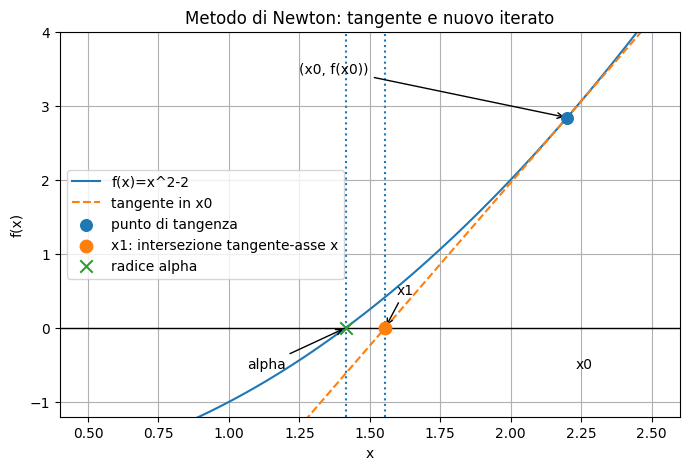

x0 = 2.2
x1 = 1.5545454545454547
radice alpha = 1.4142135623730951
|x1-alpha| = 0.14033189217235953


In [58]:
# Interpretazione geometrica di un passo del metodo di Newton.
# Scelgo x0=2.2, così il nuovo iterato x1 è ben distinto dalla radice sqrt(2).

f = lambda x: x**2 - 2
df = lambda x: 2*x

x0 = 2.2
x1 = x0 - f(x0)/df(x0)
alpha = math.sqrt(2)

xs = np.linspace(0.5, 2.5, 600)
tangent = f(x0) + df(x0) * (xs - x0)

plt.figure(figsize=(8, 5))
plt.plot(xs, f(xs), label="f(x)=x^2-2")
plt.plot(xs, tangent, "--", label="tangente in x0")
plt.axhline(0, color="black", linewidth=1)

# Punti importanti
plt.scatter([x0], [f(x0)], s=70, zorder=4, label="punto di tangenza")
plt.scatter([x1], [0], s=80, zorder=5, label="x1: intersezione tangente-asse x")
plt.scatter([alpha], [0], s=80, marker="x", zorder=5, label="radice alpha")

# Linee verticali per rendere distinguibili x1 e alpha
plt.axvline(x1, linestyle=":", linewidth=1.5)
plt.axvline(alpha, linestyle=":", linewidth=1.5)

plt.annotate("x0", xy=(x0, 0), xytext=(x0+0.03, -0.55))
plt.annotate("x1", xy=(x1, 0), xytext=(x1+0.04, 0.45),
             arrowprops=dict(arrowstyle="->"))
plt.annotate("alpha", xy=(alpha, 0), xytext=(alpha-0.35, -0.55),
             arrowprops=dict(arrowstyle="->"))
plt.annotate("(x0, f(x0))", xy=(x0, f(x0)), xytext=(1.25, f(x0)+0.6),
             arrowprops=dict(arrowstyle="->"))

plt.title("Metodo di Newton: tangente e nuovo iterato")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.ylim(-1.2, 4.0)
plt.grid(True)
plt.legend()
plt.show()

print("x0 =", x0)
print("x1 =", x1)
print("radice alpha =", alpha)
print("|x1-alpha| =", abs(x1-alpha))

In [59]:
def newton(f, df, x0, tol_x=1e-12, tol_f=1e-14, max_iter=50, return_history=False):
    x_old = float(x0)
    history = [(0, x_old, f(x_old), None)]

    for k in range(1, max_iter + 1):
        fx = f(x_old)
        dfx = df(x_old)

        if abs(dfx) < np.finfo(float).tiny:
            raise ZeroDivisionError("Derivata troppo piccola o nulla.")

        x_new = x_old - fx / dfx
        step = abs(x_new - x_old)

        history.append((k, x_new, f(x_new), step))

        if step <= tol_x + np.finfo(float).eps * min(abs(x_new), abs(x_old)):
            return (x_new, k, history, "step") if return_history else (x_new, k)
        if abs(f(x_new)) <= tol_f:
            return (x_new, k, history, "residual") if return_history else (x_new, k)

        x_old = x_new

    return (x_old, max_iter, history, "max_iter") if return_history else (x_old, max_iter)

In [60]:
f = lambda x: x**2 - 2
df = lambda x: 2*x

root, it, hist, reason = newton(f, df, x0=1.0, return_history=True)

print("Radice:", root)
print("Iterazioni:", it)
print("Motivo arresto:", reason)
print("Errore:", abs(root - math.sqrt(2)))

for k, xk, fxk, step in hist:
    print(f"k={k:2d}, x={xk:.15f}, f(x)={fxk:.3e}, step={step}")

Radice: 1.4142135623730951
Iterazioni: 5
Motivo arresto: residual
Errore: 0.0
k= 0, x=1.000000000000000, f(x)=-1.000e+00, step=None
k= 1, x=1.500000000000000, f(x)=2.500e-01, step=0.5
k= 2, x=1.416666666666667, f(x)=6.944e-03, step=0.08333333333333326
k= 3, x=1.414215686274510, f(x)=6.007e-06, step=0.002450980392156854
k= 4, x=1.414213562374690, f(x)=4.511e-12, step=2.123899820016817e-06
k= 5, x=1.414213562373095, f(x)=4.441e-16, step=1.5947243525715749e-12



*Teorema di convergenza locale del metodo di Newton*

 Sia $x^*$ uno zero di $f(x)$. Sia $f(x)$ continua insieme alle sue derivate prima,
seconda e terza.

Sia $f'(x)\neq 0$ per $x$ in un opportuno intorno di $x^*$ e sia
$f''(x^*)\neq 0$ ($f(x)/f'(x)$ deve essere definita e deve essere
$g''(x)\neq 0$).

Allora, per ogni $x_0 \in I_\rho$, la successione generata dal
metodo di Newton converge a $x^*$ in modo quadratico.

*Velocità di convergenza del metodo di Newton*

Il metodo iterativo ha quindi velocità di convergenza *quadratica*, cioè l'ordine di convergenza del metodo di Newton è p=2.



Esempio 1

  $\sin(x)-\left(\frac{x}{2}\right)^2$ in $[1,2].$

  $f'(x)=\cos(x)-\frac{x}{2}; \qquad f''(x)=-\sin(x)-\frac{1}{2}$

  $\displaystyle{x_{k+1}=x_k-\frac{\sin(x_k)-\left(\frac{x_k}{2}\right)^2}{\cos(x)-\frac{x_k}{2}}}$
  
  costante asintotica d'errore $\frac{g''(x^*)}{2}=\frac{f''(x^*)}{2f'(x^*)}\simeq0.54$

<p align="center">
  <img src="immagini_sorgente\fig108.png"  width="800">
</p>

Esempio 2

$x^2-\gamma=0$

$\displaystyle{x_{k+1}=x_k-\frac{x_k^2-\gamma}{2x_k}}=\frac{1}{2}\left( x_k + \frac{\gamma}{x_k}\right)$

Per $\gamma=2$ e $[1,2]$ si ha:

<p align="center">
  <img src="immagini_sorgente\fig109.png"  width="250">
</p>

*costante asintotica d'errore*

$\frac{f''(x^*)}{2f'(x^*)}=\frac{1}{2\sqrt{\gamma}}$; se $\gamma$
è piccolo, la convergenza può essere lenta.


*Considerazioni algoritmiche*

- I criteri di arresto del
metodo di newton sono gli stessi del metodo delle approssimazioni
successive.

- La complessità computazionale del metodo di Newton è
pari ad una valutazione della funzione e una valutazione della
derivata prima per passo.

- Se la complessit\ag di $f'$ è analoga a quella di $f$, si dice che
il metodo richiede due valutazioni di funzioni per passo.